In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df = pd.read_csv("../data/feature_engineered_data.csv")

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,Month,Day,DayOfWeek,IsWeekend,Revenue,Discount Amount,Net Revenue,Lag_1_Day,Lag_7_Days,Rolling_7_Days
0,2022-01-08,S001,P0001,Furniture,East,231,2,119,0.84,66.30,...,1,8,5,1,132.60,1326.00,-1193.40,107.0,127.0,80.285714
1,2022-01-09,S001,P0001,Electronics,South,373,350,178,352.24,41.72,...,1,9,6,1,14602.00,0.00,14602.00,2.0,81.0,62.428571
2,2022-01-10,S001,P0001,Electronics,West,327,36,132,39.50,32.68,...,1,10,0,0,1176.48,163.40,1013.08,350.0,5.0,100.857143
3,2022-01-11,S001,P0001,Furniture,West,101,16,193,16.11,27.53,...,1,11,1,0,440.48,137.65,302.83,36.0,58.0,105.285714
4,2022-01-12,S001,P0001,Toys,South,145,104,189,100.32,92.92,...,1,12,2,0,9663.68,0.00,9663.68,16.0,147.0,99.285714


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset Shape: (72400, 26)

Columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality', 'Year', 'Month', 'Day', 'DayOfWeek', 'IsWeekend', 'Revenue', 'Discount Amount', 'Net Revenue', 'Lag_1_Day', 'Lag_7_Days', 'Rolling_7_Days']


In [6]:
target = "Units Sold"

y = df[target]

print("Target:", target)
print("Target Shape:", y.shape)

Target: Units Sold
Target Shape: (72400,)


In [7]:
features = [
    "Inventory Level",
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "IsWeekend",
    "Lag_1_Day",
    "Lag_7_Days",
    "Rolling_7_Days"
]

X = df[features]
y = df["Units Sold"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (72400, 12)
Target Shape: (72400,)


In [8]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (57920, 12)
Testing Data: (14480, 12)


In [9]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [10]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[ 49.24 199.88  55.96 114.76  55.69 124.23  36.62 203.74 187.54 135.23]


In [11]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Model Performance
------------------
MAE : 69.99166298342541
RMSE: 89.85144853170624
R²  : 0.32757504333756315


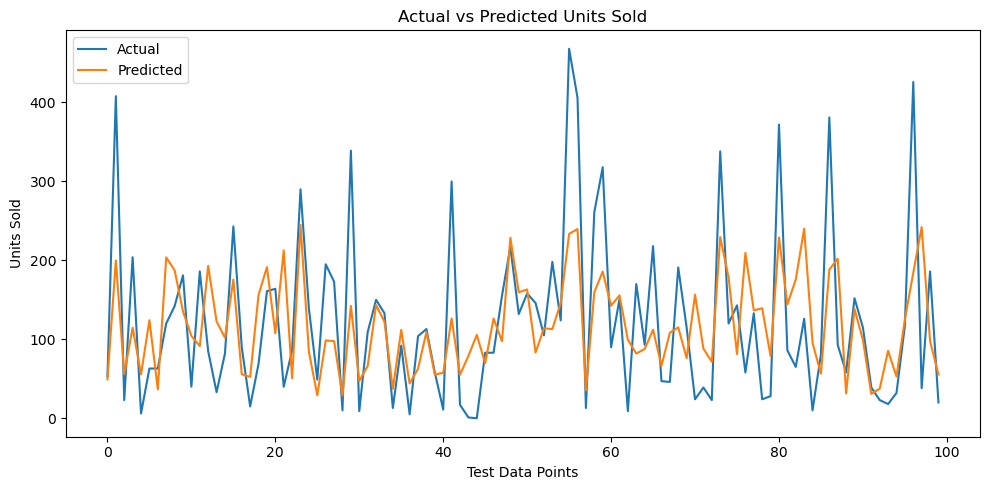

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(y_test.values[:100], label="Actual")
plt.plot(y_pred[:100], label="Predicted")

plt.title("Actual vs Predicted Units Sold")
plt.xlabel("Test Data Points")
plt.ylabel("Units Sold")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(feature_importance)

Inventory Level      0.416241
Price                0.100193
Rolling_7_Days       0.095850
Lag_7_Days           0.091391
Lag_1_Day            0.091236
Day                  0.066156
Month                0.048350
DayOfWeek            0.033822
Discount             0.029872
Year                 0.011239
Holiday/Promotion    0.011187
IsWeekend            0.004464
dtype: float64


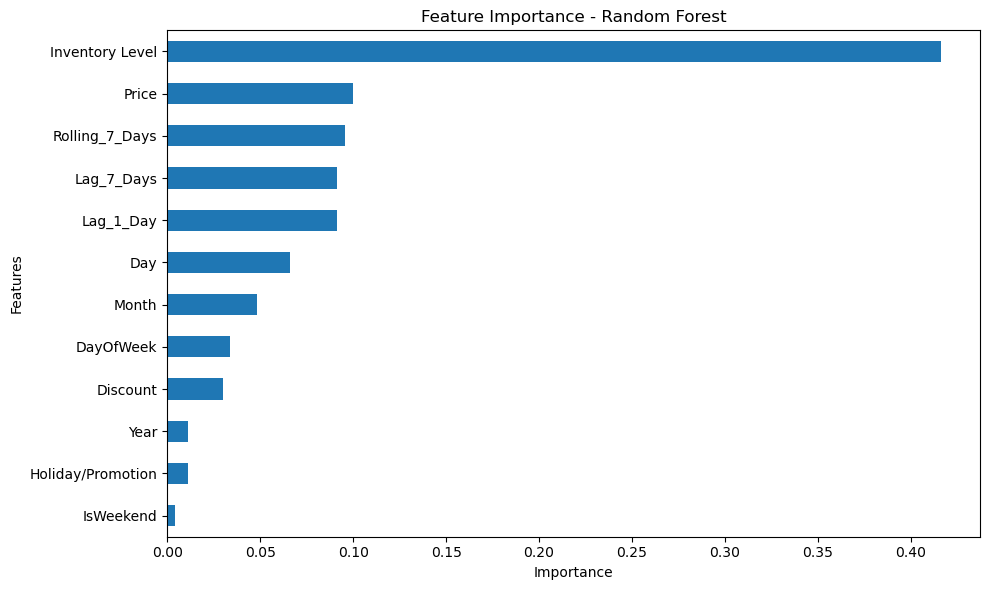

In [14]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [15]:
import joblib

joblib.dump(model, "../models/random_forest_demand_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [16]:
results = pd.DataFrame({
    "Actual_Units_Sold": y_test.values,
    "Predicted_Units_Sold": y_pred
})

results.head(10)

,Actual_Units_Sold,Predicted_Units_Sold
0,53,49.24
1,408,199.88
2,23,55.96
3,204,114.76
4,6,55.69
5,63,124.23
6,63,36.62
7,120,203.74
8,142,187.54
9,181,135.23


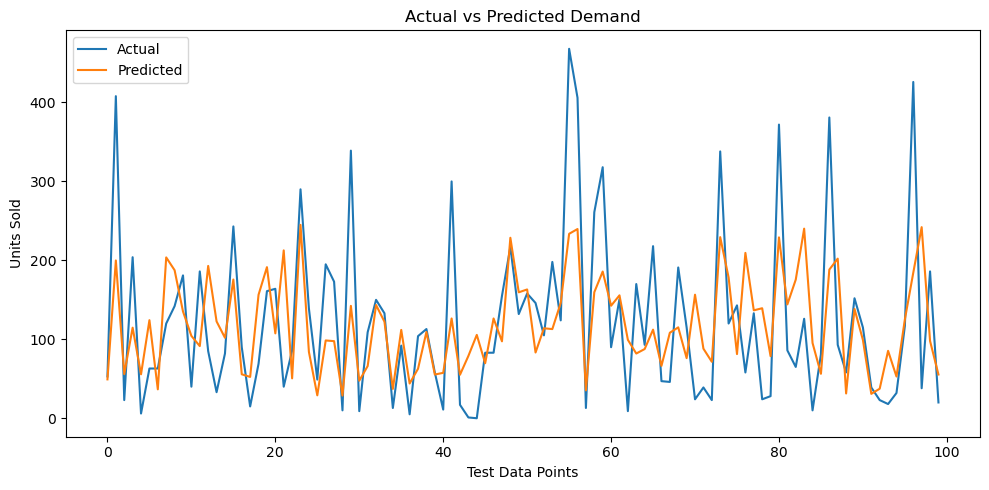

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(y_test.values[:100], label="Actual")
plt.plot(y_pred[:100], label="Predicted")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Test Data Points")
plt.ylabel("Units Sold")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Performance")
print("------------------------------")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

Gradient Boosting Performance
------------------------------
MAE : 69.07641566678656
RMSE: 88.25355999217216
R²  : 0.35127875044443657


In [19]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting"],
    "MAE": [mae, gb_mae],
    "RMSE": [rmse, gb_rmse],
    "R2": [r2, gb_r2]
})

comparison

,Model,MAE,RMSE,R2
0,Random Forest,69.991663,89.851449,0.327575
1,Gradient Boosting,69.076416,88.253560,0.351279


In [20]:
joblib.dump(gb_model, "../models/gradient_boosting_demand_model.pkl")

print("Gradient Boosting model saved successfully!")

Gradient Boosting model saved successfully!


In [21]:
print("Final Demand Forecasting Model")
print("------------------------------")
print("Model : Gradient Boosting")
print("MAE  :", gb_mae)
print("RMSE :", gb_rmse)
print("R²   :", gb_r2)

Final Demand Forecasting Model
------------------------------
Model : Gradient Boosting
MAE  : 69.07641566678656
RMSE : 88.25355999217216
R²   : 0.35127875044443657


In [22]:
final_predictions = pd.DataFrame({
    "Actual_Units_Sold": y_test.values,
    "Predicted_Units_Sold": gb_pred
})

final_predictions.to_csv(
    "../data/demand_predictions.csv",
    index=False
)

print("Prediction file saved successfully!")

Prediction file saved successfully!


In [23]:
print("Final Model Performance")
print("-----------------------")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

print("\nPrediction File Shape:")
print(final_predictions.shape)

print("\nPrediction Sample:")
print(final_predictions.head())

Final Model Performance
-----------------------
MAE : 69.07641566678656
RMSE: 88.25355999217216
R²  : 0.35127875044443657

Prediction File Shape:
(14480, 2)

Prediction Sample:
   Actual_Units_Sold  Predicted_Units_Sold
0                 53             53.841691
1                408            204.028307
2                 23             51.699219
3                204            103.561849
4                  6             65.683343


In [24]:
import pandas as pd
import joblib
from sklearn.ensemble import GradientBoostingRegressor

df = pd.read_csv("../data/feature_engineered_data.csv")

features = [
    "Inventory Level", "Price", "Discount",
    "Holiday/Promotion", "Year", "Month", "Day",
    "DayOfWeek", "IsWeekend", "Lag_1_Day",
    "Lag_7_Days", "Rolling_7_Days"
]

X = df[features]
y = df["Units Sold"]

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
y_train = y.iloc[:split]

model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

joblib.dump(
    model,
    "../models/gradient_boosting_demand_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [25]:
import sklearn
print(sklearn.__version__)

1.7.2
